# Assignment 2: Prompt Engineering and Model Fine-Tuning

**Course:** Large Language Models for Marketing  
**Dataset:** Yelp Restaurant Reviews (~19,896 reviews)  
**Dependent Variable:** Star rating (1–5)  

---

**Structure:**
1. Setup & Data Loading
2. Part 1 — System/Developer Prompt Settings
3. Part 2 — Zero / One / Few-Shot Prompting
4. Part 3 — Model Fine-Tuning (DistilBERT)


## 0 · Setup

Run the cell below once to install all required packages.

In [47]:
%pip install groq scikit-learn pandas numpy matplotlib torch transformers datasets --quiet

Note: you may need to restart the kernel to use updated packages.


In [49]:
# ── Imports ──────────────────────────────────────────────────
import os, random, time, warnings
import numpy as np
import pandas as pd
from groq import Groq
from sklearn.metrics import accuracy_score, mean_absolute_error, classification_report

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)

# ── Groq API key ──────────────────────────────────────────────
# Free at console.groq.com — no credit card needed
GROQ_API_KEY = "os.environ["GROQ_API_KEY"]"   # paste your key starting with gsk_...
CHAT_MODEL   = "llama-3.1-8b-instant" # fast, free Llama 3.1 8B on Groq

client = Groq(api_key=GROQ_API_KEY)

# Quick token check
try:
    r = client.chat.completions.create(
        model      = CHAT_MODEL,
        messages   = [{"role": "user", "content": "Say hi."}],
        max_tokens = 5,
    )
    print("Groq OK. Model:", CHAT_MODEL)
except Exception as e:
    print("Groq ERROR:", e)

Groq OK. Model: llama-3.1-8b-instant


## 1 · Load & Prepare Data

In [50]:
# ── Load the raw Yelp dataset ─────────────────────────────────
# Adjust path if needed
df = pd.read_csv("Yelp Restaurant Reviews 2.csv")
df.columns = ['url', 'stars', 'date', 'text']
df['stars'] = df['stars'].astype(int)

print(f"Total reviews: {len(df):,}")
print("\nRating distribution:")
print(df['stars'].value_counts().sort_index())

Total reviews: 19,896

Rating distribution:
stars
1     1217
2     1280
3     2069
4     4447
5    10883
Name: count, dtype: int64


In [51]:
# ── Stratified sample for Parts 1 & 2 ────────────────────────
# We use 20 reviews per star level (100 total) to stay within
# HuggingFace free-tier rate limits while covering all ratings.
SAMPLE_PER_STAR = 20

sample_parts12 = pd.concat([
    df[df['stars'] == star].sample(SAMPLE_PER_STAR, random_state=42)
    for star in [1, 2, 3, 4, 5]
]).reset_index(drop=True)

print(f"Sample size: {len(sample_parts12)} reviews (stratified, {SAMPLE_PER_STAR} per star level)")
print(sample_parts12['stars'].value_counts().sort_index())

Sample size: 100 reviews (stratified, 20 per star level)
stars
1    20
2    20
3    20
4    20
5    20
Name: count, dtype: int64


---
## Part 1 · System / Developer Prompt Settings

We compare two fundamentally different system prompt "personalities":

- **Prompt A — Academic Analyst:** Neutral, structured, focuses on linguistic patterns and objective sentiment signals.
- **Prompt B — Marketing Consultant:** Practical, action-oriented, frames insights as business recommendations.

Both prompts receive identical user messages and model parameters (temperature = 0.3, max_tokens = 250), so any difference in output is attributable solely to the system prompt.

In [52]:
# ── Define the two system prompts ────────────────────────────

SYSTEM_A = """You are an academic text analyst specializing in consumer sentiment research.
When given a restaurant review, you analyze it objectively and systematically.
Structure your response as follows:
1. Sentiment polarity (Positive / Neutral / Negative) with a brief justification.
2. Key linguistic signals (specific words or phrases that drove your assessment).
3. Predicted star rating (1–5) based on the review content.
Be concise, precise, and avoid subjective judgements beyond what the text supports."""

SYSTEM_B = """You are a marketing consultant helping restaurant owners understand customer feedback.
When given a review, extract actionable insights a restaurant manager can act on today.
Structure your response as follows:
1. Customer verdict (Satisfied / Neutral / Dissatisfied) — one sentence summary.
2. What the restaurant did well (or poorly) — from the customer's point of view.
3. One concrete recommendation the manager should implement.
4. Predicted star rating (1–5).
Write in a clear, conversational tone that a non-expert can immediately understand."""

print("Prompt A (Academic Analyst):")
print(SYSTEM_A)
print("\nPrompt B (Marketing Consultant):")
print(SYSTEM_B)

Prompt A (Academic Analyst):
You are an academic text analyst specializing in consumer sentiment research.
When given a restaurant review, you analyze it objectively and systematically.
Structure your response as follows:
1. Sentiment polarity (Positive / Neutral / Negative) with a brief justification.
2. Key linguistic signals (specific words or phrases that drove your assessment).
3. Predicted star rating (1–5) based on the review content.
Be concise, precise, and avoid subjective judgements beyond what the text supports.

Prompt B (Marketing Consultant):
You are a marketing consultant helping restaurant owners understand customer feedback.
When given a review, extract actionable insights a restaurant manager can act on today.
Structure your response as follows:
1. Customer verdict (Satisfied / Neutral / Dissatisfied) — one sentence summary.
2. What the restaurant did well (or poorly) — from the customer's point of view.
3. One concrete recommendation the manager should implement.
4.

In [53]:
# ── Helper function: call the model ──────────────────────────
def call_model(system_prompt, user_text, temperature=0.3, max_tokens=250, retries=3):
    """Call Llama 3.1 8B via Groq's free API."""
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user",   "content": user_text},
    ]
    for attempt in range(retries):
        try:
            response = client.chat.completions.create(
                model       = CHAT_MODEL,
                messages    = messages,
                max_tokens  = max_tokens,
                temperature = max(temperature, 0.01),
            )
            return response.choices[0].message.content.strip()
        except Exception as e:
            if attempt < retries - 1:
                time.sleep(5)
            else:
                return f"[ERROR: {e}]"
    return "[ERROR: max retries exceeded]"

# Sanity check
test_out = call_model("You are a helpful assistant.", "Say hello in one sentence.")
print("Test output:", test_out)

Test output: Hello, how can I assist you today?


In [54]:
# ── Select 5 diverse reviews for qualitative comparison ──────
# One review per star level so we capture the full sentiment spectrum.
showcase = pd.concat([
    df[df['stars'] == star].sample(1, random_state=7)
    for star in [1, 2, 3, 4, 5]
]).reset_index(drop=True)

print("Reviews selected for Part 1 showcase:")
for _, row in showcase.iterrows():
    print(f"\n{row['stars']}★  {row['text'][:120]}...")

Reviews selected for Part 1 showcase:

1★  AmÃ©lie's is a racist institution. They refer to black employees as "the help", decorate in blackface and have failed to...

2★  This review is based on my service. After coming here and spending a lot of money trying different pastries I made sure ...

3★  3 stars. Cupcakes were wonderful, and dependable. I live by the Newport Beach, CA store and they are exactly what I expe...

4★  This ice cream spot... First let's start with the staff. There were two brothers who make the ice cream, donuts, and run...

5★  Delicious! Great ending to a family trip to West Side Market. The interior is fresh and inviting. So glad it replaced Mo...


In [55]:
# ── Run both prompts on the 5 showcase reviews ────────────────
# This cell takes ~1–2 minutes due to API calls.
results_p1 = []

for _, row in showcase.iterrows():
    user_msg = f"Please analyze this customer review:\n\n\"{row['text']}\""
    
    resp_a = call_model(SYSTEM_A, user_msg)
    time.sleep(2)   # small delay to avoid rate limits
    resp_b = call_model(SYSTEM_B, user_msg)
    time.sleep(2)
    
    results_p1.append({
        'stars':      row['stars'],
        'review':     row['text'][:200],
        'response_A': resp_a,
        'response_B': resp_b,
    })
    print(f"Done: {row['stars']}★")

print("\nAll 5 reviews processed.")

Done: 1★
Done: 2★
Done: 3★
Done: 4★
Done: 5★

All 5 reviews processed.


In [56]:
# ── Display results side by side ─────────────────────────────
for r in results_p1:
    print("=" * 70)
    print(f"REVIEW ({r['stars']}★): {r['review'][:150]}...")
    print("-" * 35 + " PROMPT A (Academic) " + "-" * 14)
    print(r['response_A'])
    print("-" * 35 + " PROMPT B (Marketing) " + "-" * 13)
    print(r['response_B'])
    print()

REVIEW (1★): AmÃ©lie's is a racist institution. They refer to black employees as "the help", decorate in blackface and have failed to have any leaders that are not...
----------------------------------- PROMPT A (Academic) --------------
1. Sentiment polarity: Negative
Justification: The review explicitly states that Amélie's is a "racist institution" and highlights several instances of racist behavior, including the use of derogatory language and discriminatory hiring practices. The reviewer also explicitly advises others to "think twice" before giving the restaurant their money, further emphasizing the negative sentiment.

2. Key linguistic signals:
- "racist institution" (explicit accusation of racism)
- "refer to black employees as 'the help'" (derogatory language)
- "decorate in blackface" (racist imagery)
- "failed to have any leaders that are not white" (discriminatory hiring practices)
- "Leadership has referred to their black employees as people who were not 'otherwise employa

In [57]:
# ── AI reflection: ask the model to compare its own outputs ──
# We show the model one pair of outputs and ask it to reflect
# on how the different system prompts shaped the responses.

example = results_p1[2]   # use the 3-star review as illustrative case

reflection_prompt = f"""Below are two AI-generated analyses of the same restaurant review, 
produced under two different system prompt configurations.

REVIEW: "{example['review']}"

--- RESPONSE A (Academic Analyst prompt) ---
{example['response_A']}

--- RESPONSE B (Marketing Consultant prompt) ---
{example['response_B']}

In 150–200 words, reflect on:
1. How do the two responses differ in tone, structure, and focus?
2. Which prompt setting is more useful for a restaurant owner, and why?
3. What are the trade-offs between the two approaches?"""

SYSTEM_REFLECTION = "You are an expert in prompt engineering and natural language processing."

ai_reflection = call_model(SYSTEM_REFLECTION, reflection_prompt, temperature=0.5, max_tokens=350)
print("=" * 70)
print("AI REFLECTION ON PROMPT DIFFERENCES")
print("=" * 70)
print(ai_reflection)

AI REFLECTION ON PROMPT DIFFERENCES
The two responses demonstrate distinct differences in tone, structure, and focus, reflecting the unique objectives of the respective prompts. Response A (Academic Analyst) is more formal, objective, and analytical, focusing on sentiment analysis, linguistic signals, and predicted star ratings. The tone is neutral, and the language is technical.

In contrast, Response B (Marketing Consultant) is more practical, actionable, and solution-oriented, focusing on customer verdict, strengths and weaknesses, and concrete recommendations for improvement. The tone is advisory, and the language is more conversational.

A restaurant owner may find Response B more useful, as it provides actionable insights and recommendations for improvement. The Marketing Consultant prompt encourages the analysis of customer feedback to inform business decisions, which is critical for a restaurant owner seeking to enhance customer satisfaction and loyalty.

The trade-offs between

---
## Part 2 · Zero / One / Few-Shot Prompting

We evaluate how well the model predicts the true star rating (1–5) when given
different numbers of labeled examples in the prompt:

| Setting | Examples in prompt |
|---|---|
| Zero-shot | None — model relies on general knowledge |
| One-shot (positive) | 1 example: a 5-star review |
| One-shot (negative) | 1 example: a 1-star review |
| Few-shot | 5 examples (one per star level) |

**Evaluation metrics:** Exact accuracy and Mean Absolute Error (MAE) on 100 reviews.

In [58]:
# ── Fixed system prompt for all shot experiments ──────────────
# We keep the system prompt identical across all conditions;
# only the number of in-context examples changes.
SYSTEM_SHOTS = """You are a review rating predictor. Your only task is to predict 
the star rating (1, 2, 3, 4, or 5) a customer gave to a restaurant, 
based solely on their review text.
Reply with a single integer between 1 and 5. No explanation, no extra text."""

print("System prompt set.")

System prompt set.


In [59]:
# ── Fixed example reviews used in one-shot / few-shot ─────────
# These are drawn from reviews NOT in our evaluation sample.

EXAMPLE_POSITIVE = {
    'text': "Absolutely amazing! The food was fresh, the staff was incredibly friendly, "
            "and the portions were generous. Best ice cream I've ever had. Will definitely come back!",
    'label': 5
}

EXAMPLE_NEGATIVE = {
    'text': "Terrible experience. The ice cream tasted artificial, the staff ignored us for 10 minutes, "
            "and the place was dirty. Never coming back.",
    'label': 1
}

EXAMPLES_FEW = [
    {'text': "Absolutely disgusting. Found a hair in my food and the manager refused to help. "
             "Total waste of money.",                                                            'label': 1},
    {'text': "Below average. The ice cream was okay but the service was slow and the price too high.", 'label': 2},
    {'text': "It was fine. Nothing special, but nothing bad either. Average ice cream shop.",          'label': 3},
    {'text': "Really enjoyed it! Great flavors and friendly staff. Would visit again.",               'label': 4},
    {'text': "Phenomenal! Best dessert place in town. Creative flavors, generous portions, "
             "and outstanding service. Highly recommend!",                                           'label': 5},
]

print("Example reviews defined.")

Example reviews defined.


In [60]:
# ── Helper: build a prompt with N examples ────────────────────
def build_user_message(review_text, examples=None):
    """Construct the user message, optionally prepending labeled examples."""
    msg = ""
    if examples:
        msg += "Here are some example reviews with their correct ratings:\n\n"
        for ex in examples:
            msg += f'Review: "{ex["text"]}"\nRating: {ex["label"]}\n\n'
        msg += "Now predict the rating for this new review:\n\n"
    msg += f'Review: "{review_text}"\nRating:'
    return msg

# ── Helper: parse the model's integer response ────────────────
def parse_rating(response):
    """Extract the first digit 1–5 from the model's response."""
    for char in str(response).strip():
        if char in '12345':
            return int(char)
    return None   # could not parse

print("Helper functions defined.")

Helper functions defined.


In [61]:
# ── Run all four shot conditions ──────────────────────────────
# We use our 100-review stratified sample (sample_parts12).
# Each condition makes one API call per review → ~400 calls total.
# Expected runtime: 15–25 minutes.

conditions = {
    'zero_shot':         None,
    'one_shot_positive': [EXAMPLE_POSITIVE],
    'one_shot_negative': [EXAMPLE_NEGATIVE],
    'few_shot':          EXAMPLES_FEW,
}

all_results = {name: [] for name in conditions}
true_labels  = sample_parts12['stars'].tolist()

for cond_name, examples in conditions.items():
    print(f"\nRunning: {cond_name} ...")
    preds = []
    for i, row in sample_parts12.iterrows():
        user_msg = build_user_message(row['text'], examples)
        raw      = call_model(SYSTEM_SHOTS, user_msg, temperature=0.1, max_tokens=5)
        pred     = parse_rating(raw)
        preds.append(pred)
        time.sleep(1.5)   # respect rate limits
        if (len(preds) % 20) == 0:
            print(f"  {len(preds)}/100 done")
    all_results[cond_name] = preds
    print(f"  Finished {cond_name}.")

print("\nAll conditions complete.")


Running: zero_shot ...
  20/100 done
  40/100 done
  60/100 done
  80/100 done
  100/100 done
  Finished zero_shot.

Running: one_shot_positive ...
  20/100 done
  40/100 done
  60/100 done
  80/100 done
  100/100 done
  Finished one_shot_positive.

Running: one_shot_negative ...
  20/100 done
  40/100 done
  60/100 done
  80/100 done
  100/100 done
  Finished one_shot_negative.

Running: few_shot ...
  20/100 done
  40/100 done
  60/100 done
  80/100 done
  100/100 done
  Finished few_shot.

All conditions complete.


In [62]:
# ── Compute metrics ───────────────────────────────────────────
rows_metrics = []
for cond_name, preds in all_results.items():
    # Filter out reviews where parsing failed
    valid = [(t, p) for t, p in zip(true_labels, preds) if p is not None]
    if not valid:
        continue
    t_vals, p_vals = zip(*valid)
    acc  = accuracy_score(t_vals, p_vals)
    mae  = mean_absolute_error(t_vals, p_vals)
    n_ok = len(valid)
    rows_metrics.append({'Condition': cond_name, 'N valid': n_ok,
                         'Accuracy': round(acc, 3), 'MAE': round(mae, 3)})

metrics_df = pd.DataFrame(rows_metrics)
print(metrics_df.to_string(index=False))

        Condition  N valid  Accuracy  MAE
        zero_shot      100      0.66 0.36
one_shot_positive      100      0.55 0.48
one_shot_negative      100      0.51 0.58
         few_shot      100      0.54 0.50


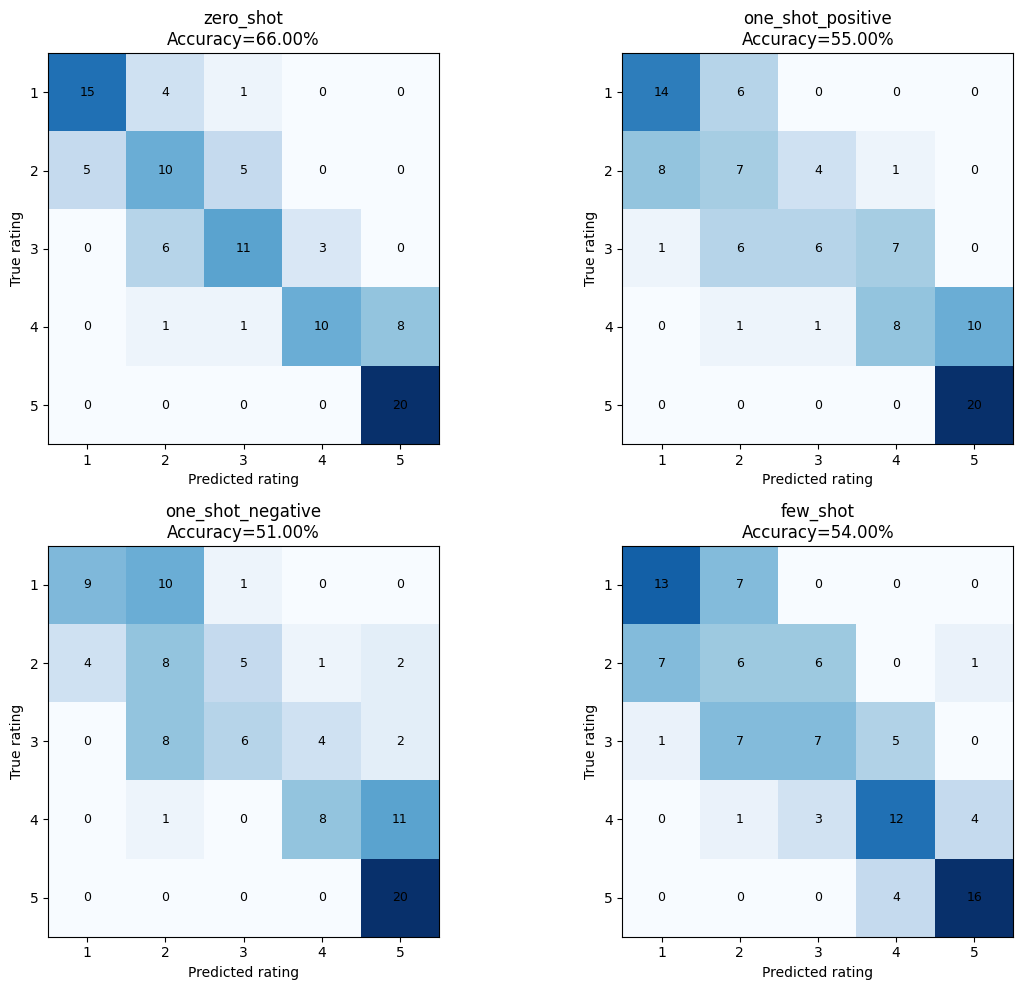

Figure saved.


In [63]:
# ── Confusion-style breakdown: predicted vs true per condition ─
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (cond_name, preds) in zip(axes, all_results.items()):
    valid = [(t, p) for t, p in zip(true_labels, preds) if p is not None]
    if not valid:
        continue
    t_vals, p_vals = zip(*valid)
    conf = pd.crosstab(pd.Series(t_vals, name='True'),
                       pd.Series(p_vals, name='Predicted'))
    im = ax.imshow(conf.values, cmap='Blues')
    ax.set_xticks(range(len(conf.columns))); ax.set_xticklabels(conf.columns)
    ax.set_yticks(range(len(conf.index)));   ax.set_yticklabels(conf.index)
    ax.set_xlabel('Predicted rating')
    ax.set_ylabel('True rating')
    acc = accuracy_score(t_vals, p_vals)
    ax.set_title(f"{cond_name}\nAccuracy={acc:.2%}")
    for i in range(len(conf.index)):
        for j in range(len(conf.columns)):
            ax.text(j, i, conf.values[i, j], ha='center', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('part2_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved.")

In [64]:
# ── One-shot positive vs negative: deeper look ───────────────
# Compare how the model's predictions differ when primed with
# a positive vs a negative example.

pos_preds = all_results['one_shot_positive']
neg_preds = all_results['one_shot_negative']

valid_pn = [(t, p, n) for t, p, n in zip(true_labels, pos_preds, neg_preds)
            if p is not None and n is not None]
t_v, p_v, n_v = zip(*valid_pn)

df_pn = pd.DataFrame({'true': t_v, 'pos_pred': p_v, 'neg_pred': n_v})
print("Mean predicted rating per true rating (one-shot positive):")
print(df_pn.groupby('true')['pos_pred'].mean().round(2))
print("\nMean predicted rating per true rating (one-shot negative):")
print(df_pn.groupby('true')['neg_pred'].mean().round(2))

print(f"\nOverall mean prediction — positive example: {np.mean(p_v):.2f}")
print(f"Overall mean prediction — negative example: {np.mean(n_v):.2f}")

Mean predicted rating per true rating (one-shot positive):
true
1    1.30
2    1.90
3    2.95
4    4.35
5    5.00
Name: pos_pred, dtype: float64

Mean predicted rating per true rating (one-shot negative):
true
1    1.60
2    2.45
3    3.00
4    4.45
5    5.00
Name: neg_pred, dtype: float64

Overall mean prediction — positive example: 3.10
Overall mean prediction — negative example: 3.30


---
## Summary

Parts 1 and 2 are complete. See  for the fine-tuning results (Part 3).
